# Análisis Exploratorio de Datos (EDA) - BCMM
# Exploratory Data Analysis (EDA) - BCMM

**Español:** Este notebook documenta la carga, limpieza, análisis estructural y diagnóstico del modelo predictivo para la Balanza Comercial de Mercancías de México (INEGI).

**English:** This notebook documents the loading, cleaning, structural analysis, and predictive model diagnostics for the Mexican Merchandise Trade Balance (INEGI).

## 1. Configuración Inicial / Initial Setup

**Español:** Importación de librerías y configuración de opciones de Pandas para visualización de datos.

**English:** Library imports and Pandas configuration options for data visualization.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

RAW_DIR = Path("../data/raw")
print(f"Directorio de datos / Data directory: {RAW_DIR.resolve()}")

Directorio de datos / Data directory: C:\Users\Cyrene\Documents\Escolar\machine-learning-zoomcamp\homework\Midterm_Project\data\raw


## 2. Carga y Validación de Archivos / File Loading & Validation

**Español:** Carga de los archivos CSV y verificación de consistencia en las columnas.

**English:** Loading CSV files and verifying column consistency.

In [2]:
files = sorted(RAW_DIR.glob("bcmm_paises_bien_mensual_tr_cifra_*.csv"))
print(f"Archivos encontrados / Files found: {len(files)}")
for f in files:
    print(f" - {f.name}")

dfs = {f.stem: pd.read_csv(f) for f in files}

# Verificar consistencia de columnas / Verify column consistency
col_sets = [set(df.columns) for df in dfs.values()]
assert all(cs == col_sets[0] for cs in col_sets), "Error: Columnas inconsistentes / Inconsistent columns"
print("\nEstado: Columnas consistentes en todos los archivos / Status: Consistent columns across all files.")
print(f"Columnas / Columns: {list(col_sets[0])}")

Archivos encontrados / Files found: 3
 - bcmm_paises_bien_mensual_tr_cifra_2015_2022.csv
 - bcmm_paises_bien_mensual_tr_cifra_2023_2025.csv
 - bcmm_paises_bien_mensual_tr_cifra_2026.csv

Estado: Columnas consistentes en todos los archivos / Status: Consistent columns across all files.
Columnas / Columns: ['MES', 'ANIO', 'PAIS_O_D', 'CLAVE_CONTINENTE', 'COBERTURA', 'CLAVE_REGION', 'ESTATUS_CIFRA', 'ESTATUS', 'PROD_EST', 'VAL_USD', 'TIPO_BIEN', 'TIPO']


In [3]:
# Concatenar datasets / Concatenate datasets
df = pd.concat(
    [d.assign(ARCHIVO_ORIGEN=name) for name, d in dfs.items()],
    ignore_index=True,
)
print(f"Dimensiones totales / Total shape: {df.shape}")
print("\nFilas por archivo / Rows per file:")
print(df["ARCHIVO_ORIGEN"].value_counts().sort_index())
df.head()

Dimensiones totales / Total shape: (216792, 13)

Filas por archivo / Rows per file:
ARCHIVO_ORIGEN
bcmm_paises_bien_mensual_tr_cifra_2015_2022    148680
bcmm_paises_bien_mensual_tr_cifra_2023_2025     55728
bcmm_paises_bien_mensual_tr_cifra_2026          12384
Name: count, dtype: int64


,PROD_EST,COBERTURA,ANIO,MES,TIPO,TIPO_BIEN,CLAVE_CONTINENTE,CLAVE_REGION,PAIS_O_D,VAL_USD,ESTATUS_CIFRA,ESTATUS,ARCHIVO_ORIGEN
0,Balanza Comercial de Mercancías de México por ...,Nacional,2015,1,Exportaciones,Consumo,NaN,NaN,NaN,"6,234,029.00",Disponible,Cifras Definitivas.,bcmm_paises_bien_mensual_tr_cifra_2015_2022
1,Balanza Comercial de Mercancías de México por ...,Nacional,2015,1,Exportaciones,Consumo,C01,NaN,NaN,"5,636,184.00",Disponible,Cifras Definitivas.,bcmm_paises_bien_mensual_tr_cifra_2015_2022
2,Balanza Comercial de Mercancías de México por ...,Nacional,2015,1,Exportaciones,Consumo,C01,R01,NaN,"5,047,148.00",Disponible,Cifras Definitivas.,bcmm_paises_bien_mensual_tr_cifra_2015_2022
3,Balanza Comercial de Mercancías de México por ...,Nacional,2015,1,Exportaciones,Consumo,C01,R01,CAN,"261,839.00",Disponible,Cifras Definitivas.,bcmm_paises_bien_mensual_tr_cifra_2015_2022
4,Balanza Comercial de Mercancías de México por ...,Nacional,2015,1,Exportaciones,Consumo,C01,R01,USA,"4,785,309.00",Disponible,Cifras Definitivas.,bcmm_paises_bien_mensual_tr_cifra_2015_2022


## 3. Diagnóstico de Calidad de Datos / Data Quality Diagnostics

**Español:** Análisis de valores nulos, tipos de datos y registros confidenciales (representados por 'C').

**English:** Analysis of null values, data types, and confidential records (represented by 'C').

In [4]:
df.info()

print("\n--- Valores faltantes por columna / Missing values per column ---")
missing = df.isna().sum()
if missing.any():
    print(missing[missing > 0])
else:
    print("No se detectaron valores nulos explícitos / No explicit null values detected.")

<class 'pandas.DataFrame'>
RangeIndex: 216792 entries, 0 to 216791
Data columns (total 13 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   PROD_EST          216792 non-null  str    
 1   COBERTURA         216792 non-null  str    
 2   ANIO              216792 non-null  int64  
 3   MES               216792 non-null  int64  
 4   TIPO              216792 non-null  str    
 5   TIPO_BIEN         216792 non-null  str    
 6   CLAVE_CONTINENTE  215112 non-null  str    
 7   CLAVE_REGION      190752 non-null  str    
 8   PAIS_O_D          200832 non-null  str    
 9   VAL_USD           182164 non-null  float64
 10  ESTATUS_CIFRA     216792 non-null  str    
 11  ESTATUS           216792 non-null  str    
 12  ARCHIVO_ORIGEN    216792 non-null  str    
dtypes: float64(1), int64(2), str(10)
memory usage: 63.9 MB

--- Valores faltantes por columna / Missing values per column ---
CLAVE_CONTINENTE     1680
CLAVE_REGION        26040
P

In [5]:
print(f"Tipo de dato de VAL_USD / Data type of VAL_USD: {df['VAL_USD'].dtype}")

# Identificar registros confidenciales ('C') / Identify confidential records ('C')
mask_c = df["VAL_USD"].astype(str).str.strip().str.upper() == "C"
print(f"\nRegistros confidenciales / Confidential records: {mask_c.sum():,} ({mask_c.mean()*100:.2f}%)")

print("\nDistribución de confidenciales por año / Distribution of confidentials by year:")
print(
    df.assign(es_C=mask_c)
      .groupby("ANIO")["es_C"]
      .agg(total="size", confidenciales="sum")
      .assign(pct=lambda x: (x["confidenciales"]/x["total"]*100).round(2))
)

Tipo de dato de VAL_USD / Data type of VAL_USD: float64

Registros confidenciales / Confidential records: 0 (0.00%)

Distribución de confidenciales por año / Distribution of confidentials by year:
      total  confidenciales  pct
ANIO                            
2015  18576               0 0.00
2016  18576               0 0.00
2017  18576               0 0.00
2018  18576               0 0.00
2019  18576               0 0.00
2020  18648               0 0.00
2021  18576               0 0.00
2022  18576               0 0.00
2023  18576               0 0.00
2024  18576               0 0.00
2025  18576               0 0.00
2026  12384               0 0.00


In [6]:
print("ESTATUS por ARCHIVO_ORIGEN / ESTATUS by ARCHIVO_ORIGEN:")
print(pd.crosstab(df["ARCHIVO_ORIGEN"], df["ESTATUS"], margins=True))

print("\nESTATUS_CIFRA por ARCHIVO_ORIGEN / ESTATUS_CIFRA by ARCHIVO_ORIGEN:")
print(pd.crosstab(df["ARCHIVO_ORIGEN"], df["ESTATUS_CIFRA"], margins=True))

ESTATUS por ARCHIVO_ORIGEN / ESTATUS by ARCHIVO_ORIGEN:
ESTATUS                                      Cifras Ajustadas.  \
ARCHIVO_ORIGEN                                                   
bcmm_paises_bien_mensual_tr_cifra_2015_2022                  0   
bcmm_paises_bien_mensual_tr_cifra_2023_2025              55728   
bcmm_paises_bien_mensual_tr_cifra_2026                       0   
All                                                      55728   

ESTATUS                                      Cifras Definitivas.  \
ARCHIVO_ORIGEN                                                     
bcmm_paises_bien_mensual_tr_cifra_2015_2022               148680   
bcmm_paises_bien_mensual_tr_cifra_2023_2025                    0   
bcmm_paises_bien_mensual_tr_cifra_2026                         0   
All                                                       148680   

ESTATUS                                      Cifras Revisadas.     All  
ARCHIVO_ORIGEN                                                   

## 4. Análisis Temporal y Categórico / Temporal & Categorical Analysis

**Español:** Evaluación del rango temporal, posibles huecos en los datos y distribución de variables categóricas.

**English:** Evaluation of the temporal range, potential data gaps, and categorical variable distribution.

In [7]:
df["periodo"] = pd.to_datetime(
    dict(year=df["ANIO"].astype(int), month=df["MES"].astype(int), day=1)
)
print(f"Rango temporal / Temporal range: {df['periodo'].min().strftime('%Y-%m')} a / to {df['periodo'].max().strftime('%Y-%m')}")

# Verificar meses con menos registros / Check months with fewer records
conteo_mensual = df.groupby("periodo").size()
print("\nMeses con menos registros (posibles huecos) / Months with fewer records (potential gaps):")
print(conteo_mensual.sort_values().head(10))

Rango temporal / Temporal range: 2015-01 a / to 2026-08

Meses con menos registros (posibles huecos) / Months with fewer records (potential gaps):
periodo
2015-01-01    1548
2015-02-01    1548
2015-03-01    1548
2015-04-01    1548
2015-05-01    1548
2015-06-01    1548
2015-07-01    1548
2015-08-01    1548
2015-09-01    1548
2015-10-01    1548
dtype: int64


In [8]:
for col in ["PAIS_O_D", "CLAVE_CONTINENTE", "CLAVE_REGION", "TIPO", "TIPO_BIEN"]:
    print(f"{col:20s} : {df[col].nunique()} valores únicos / unique values")

print("\nTIPO:", df["TIPO"].value_counts().to_dict())
print("TIPO_BIEN:", df["TIPO_BIEN"].value_counts().to_dict())
print("CLAVE_CONTINENTE:", df["CLAVE_CONTINENTE"].value_counts().to_dict())

PAIS_O_D             : 239 valores únicos / unique values
CLAVE_CONTINENTE     : 5 valores únicos / unique values
CLAVE_REGION         : 13 valores únicos / unique values
TIPO                 : 2 valores únicos / unique values
TIPO_BIEN            : 3 valores únicos / unique values

TIPO: {'Exportaciones': 108396, 'Importaciones': 108396}
TIPO_BIEN: {'Consumo': 72264, 'Intermedio': 72264, 'Capital': 72264}
CLAVE_CONTINENTE: {'C04': 50400, 'C01': 49560, 'C02': 47112, 'C03': 45360, 'C05': 22680}


In [9]:
# Validación de duplicados por clave natural / Duplicate validation by natural key
keys = ["ANIO", "MES", "TIPO", "TIPO_BIEN", "CLAVE_CONTINENTE", "CLAVE_REGION", "PAIS_O_D"]
dups = df.duplicated(subset=keys, keep=False)
print(f"Filas duplicadas por clave natural / Duplicate rows by natural key: {dups.sum():,}")
if dups.any():
    print(df[dups].sort_values(keys).head(20))

Filas duplicadas por clave natural / Duplicate rows by natural key: 0


## 5. Filtrado y Preparación del Target / Target Filtering & Preparation

**Español:** Aislamiento de datos a nivel país, análisis de confidencialidad y distribución de la variable objetivo (VAL_USD).

**English:** Isolating country-level data, confidentiality analysis, and target variable (VAL_USD) distribution.

In [10]:
# 1) Filtrar al nivel país / Filter to country level
df_pais = df[df["PAIS_O_D"].notna()].copy()
print(f"Filas nivel país / Country-level rows: {len(df_pais):,} ({len(df_pais)/len(df)*100:.1f}% del total / of total)")

# 2) Análisis de confidenciales / Confidential analysis
conf = df_pais["VAL_USD"].isna()
print(f"Confidenciales a nivel país / Country-level confidentials: {conf.sum():,} ({conf.mean()*100:.2f}%)")

print("\nConfidenciales por TIPO y TIPO_BIEN (%) / Confidentials by TIPO and TIPO_BIEN (%):")
tabla = (
    df_pais.assign(es_conf=conf)
           .groupby(["TIPO", "TIPO_BIEN"])["es_conf"]
           .mean().mul(100).round(2).unstack()
)
print(tabla)

print("\nTop 15 países por % de confidenciales / Top 15 countries by % of confidentials:")
top_conf = (
    df_pais.assign(es_conf=conf)
           .groupby("PAIS_O_D")["es_conf"]
           .agg(total="size", pct=lambda x: x.mean()*100)
           .query("total >= 100")
           .sort_values("pct", ascending=False)
           .head(15)
)
print(top_conf.round(2))

Filas nivel país / Country-level rows: 200,832 (92.6% del total / of total)
Confidenciales a nivel país / Country-level confidentials: 34,628 (17.24%)

Confidenciales por TIPO y TIPO_BIEN (%) / Confidentials by TIPO and TIPO_BIEN (%):
TIPO_BIEN      Capital  Consumo  Intermedio
TIPO                                       
Exportaciones    17.97    17.97       17.97
Importaciones    16.52    16.51       16.52

Top 15 países por % de confidenciales / Top 15 countries by % of confidentials:
          total   pct
PAIS_O_D             
PNG         840 63.21
GIB         840 60.00
LBR         840 58.21
DJI         840 57.14
BEN         840 54.29
TGO         840 53.93
COD         840 53.57
ZMB         840 52.50
LBY         840 51.79
MNG         840 50.71
GUF         840 50.00
GLP         840 50.00
GIN         840 48.93
PYF         840 47.86
MHL         840 47.38


Filas para modelado / Rows for modeling: 166,204

Estadísticos de VAL_USD (miles de USD) / VAL_USD statistics (thousands USD):
count       166,204.00
mean         72,495.25
std         794,349.26
min               0.00
1%                0.00
25%               0.00
50%             109.00
75%           4,846.00
99%         935,735.44
max      39,695,678.00
Name: VAL_USD, dtype: str


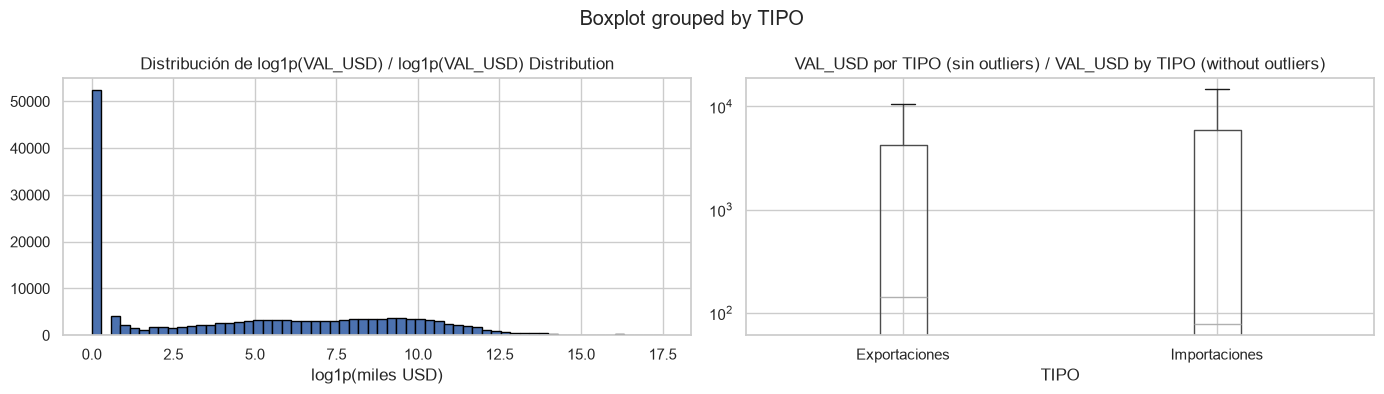

In [11]:
# Eliminar confidenciales para modelado / Drop confidentials for modeling
df_model = df_pais.dropna(subset=["VAL_USD"]).copy()
print(f"Filas para modelado / Rows for modeling: {len(df_model):,}")

print("\nEstadísticos de VAL_USD (miles de USD) / VAL_USD statistics (thousands USD):")
print(df_model["VAL_USD"].describe(percentiles=[.01, .25, .5, .75, .99]).apply(lambda x: f"{x:,.2f}"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(np.log1p(df_model["VAL_USD"]), bins=60, edgecolor="black")
axes[0].set_title("Distribución de log1p(VAL_USD) / log1p(VAL_USD) Distribution")
axes[0].set_xlabel("log1p(miles USD)")

df_model.boxplot(column="VAL_USD", by="TIPO", ax=axes[1], showfliers=False)
axes[1].set_title("VAL_USD por TIPO (sin outliers) / VAL_USD by TIPO (without outliers)")
axes[1].set_yscale("log")
plt.tight_layout()
plt.show()

## 6. Diagnóstico del Modelo (Gap Val/Test) / Model Diagnostics (Val/Test Gap)

**Español:** Evaluación del rendimiento del modelo entrenado cargando el bundle de producción. Se analizan los errores por año, tipo de flujo y países con mayor margen de error.

**English:** Evaluation of the trained model's performance by loading the production bundle. Errors are analyzed by year, trade flow, and countries with the highest margin of error.

> **Nota técnica / Technical note:** Se carga `bundle.pkl` (generado en el script de entrenamiento) en lugar de `model.pkl` para mantener la consistencia con la arquitectura de la API.

In [12]:
import sys
import joblib
from sklearn.metrics import r2_score, mean_absolute_error

# Añadir la raíz del proyecto al path / Add project root to path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_and_clean
from src.features import build_features, temporal_split

# Cargar artefactos / Load artifacts
bundle_path = PROJECT_ROOT / "models" / "bundle.pkl"
if not bundle_path.exists():
    raise FileNotFoundError(f"No se encontró el modelo en {bundle_path}. Ejecute 'python -m src.train' primero.")

bundle = joblib.load(bundle_path)
model = bundle["pipeline"]
print(f"Modelo cargado / Model loaded: {bundle['winner_name']} (v{bundle['version']})")

# Preparar datos / Prepare data
df_eval = build_features(load_and_clean())
train, val, test = temporal_split(df_eval)

# Evaluación / Evaluation
for name, split in [("Validación / Validation", val), ("Prueba / Test", test)]:
    y_true = split["VAL_USD"].values
    y_pred = np.expm1(model.predict(split))
    split_eval = split.assign(y_pred=y_pred, resid=y_true - y_pred)

    print(f"\n=== {name.upper()} ===")
    
    print("\nR2 por año / R2 by year:")
    print(split_eval.groupby("ANIO").apply(
        lambda g: pd.Series({
            "n": len(g),
            "R2": r2_score(g["VAL_USD"], g["y_pred"]),
            "MAE": mean_absolute_error(g["VAL_USD"], g["y_pred"]),
        }),
        include_groups=False,
    ).round(4))

    print("\nR2 por TIPO / R2 by TIPO:")
    print(split_eval.groupby("TIPO").apply(
        lambda g: pd.Series({
            "R2": r2_score(g["VAL_USD"], g["y_pred"]),
            "MAE": mean_absolute_error(g["VAL_USD"], g["y_pred"]),
        }),
        include_groups=False,
    ).round(4))

    split_eval["err_rel"] = np.abs(split_eval["resid"]) / (split_eval["VAL_USD"] + 1)
    top_err = (
        split_eval.groupby("PAIS_O_D")["err_rel"]
             .agg(["mean", "size"])
             .query("size >= 50")
             .sort_values("mean", ascending=False)
             .head(5)
    )
    print("\nTop 5 países con peor error relativo / Top 5 countries with highest relative error:")
    print(top_err.round(3))

Modelo cargado / Model loaded: xgb (v1.0.0)
Datos procesados guardados en: C:\Users\Cyrene\Documents\Escolar\machine-learning-zoomcamp\homework\Midterm_Project\data\processed\bcmm_pais_clean.parquet (166,204 filas)

=== VALIDACIÓN / VALIDATION ===

R2 por año / R2 by year:
             n   R2       MAE
ANIO                         
2024 14,415.00 0.98 13,933.02

R2 por TIPO / R2 by TIPO:
                R2       MAE
TIPO                        
Exportaciones 0.98 12,506.74
Importaciones 0.99 15,333.99

Top 5 países con peor error relativo / Top 5 countries with highest relative error:
          mean  size
PAIS_O_D            
PAK      88.84    72
KWT      47.18    69
SVK      33.72    72
DZA      32.70    69
VGB      26.82    66

=== PRUEBA / TEST ===

R2 por año / R2 by year:
             n   R2       MAE
ANIO                         
2025 14,325.00 0.94 20,512.42
2026  9,513.00 0.76 40,783.93

R2 por TIPO / R2 by TIPO:
                R2       MAE
TIPO                        
Exporta